# Day 9 · Run all three: success, cost, latency

**First-principles question:** Is the extra intelligence worth its price and its wait?

The full task (learn → build → record) is in this folder's `README.md`. This notebook is your workbench:
run cells top to bottom with **Shift + Enter**, fill in every cell marked **TODO**, and finish with the
**✅ self-check** cell at the end.

**First, move your code into `lab/`** (copy and paste, 5 minutes): version B from day 6 into
`lab/version_b.py`, the agent loop from day 8 into `lab/agent.py`. Keep the signatures shown at the top of each
file. From now on every notebook imports them.

In [3]:
import sys
from pathlib import Path

def find_root():
    """The fde-first-principles folder (it has progress.json)."""
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / ".learn" / "progress.json").exists() or (p / "progress.json").exists():
            return p
    raise RuntimeError("Open this notebook from inside your fde-first-principles folder.")

ROOT = find_root()
sys.path.insert(0, str(ROOT))  # so `import lab.…` works

import math
import numpy as np
import pandas as pd
import json
import matplotlib.pyplot as plt
from lab.acme import load_cases, load_results, save_results
from lab.agent import run_agent
from lab.evals import score
from lab.acme_tools import FUNCTIONS, TOOLS
from lab.llm import chat, extract_json

cases = load_cases()
by_id = {c["id"]: c for c in cases}

## 1 · Run version C on every case
Cached, so this is slow only the first time.

In [5]:
SYSTEM_C = """You are a support agent for Acme Fibre, a broadband company in Pune.
Use the tools: always look up the customer first, then search the help articles you need.
Follow every rule in the policy (exact times are never promised; refunds above ₹500 need a human;
never ask for OTPs or passwords). Call escalate when a human is needed.
When you are done, answer ONLY with JSON: {"intent": one of billing, outage, speed, cancel, upgrade,
relocation, other; "reply": the email to send; "needs_human": true or false}."""

MAX_STEPS = 6

def run_agent(case, temperature=0.0, run=0):
    messages = [{"role": "system", "content": SYSTEM_C},
                {"role": "user", "content": f"Customer id: {case['customer_id']}\n\nEmail:\n{case['message']}"}]
    trace = []
    for step in range(MAX_STEPS):
        r = chat(messages, tools=TOOLS, temperature=temperature, run=run)
        entry = {"step": step, "tokens_in": r["tokens_in"], "tokens_out": r["tokens_out"],
                 "seconds": r["seconds"], "tool_calls": []}
        trace.append(entry)
        
        messages.append(r["message"])
        if not r["tool_calls"]:
            try:
                return extract_json(r["content"]), trace
            except ValueError:
                return {"intent": "other", "reply": r["content"], "needs_human": True, "parse_error": True}, trace
        for call in r["tool_calls"]:
            name = call["function"]["name"]
            args = call["function"]["arguments"]
            if name not in FUNCTIONS:
                result = {"error": f"unknown tool {name}"}
            else:
                try:
                    result = FUNCTIONS[name](**args)
                except TypeError as e:
                    result = {"error": f"bad arguments for {name}: {e}"}
            messages.append({"role": "tool", "tool_name": name, "content": json.dumps(result, ensure_ascii=False)})
            entry["tool_calls"].append((name, args, result))

    return {"intent": "other", "reply": "", "needs_human": True, "gave_up": True}, trace


CHECKPOINT = ROOT / "data" / "results" / "C.jsonl"

# resume support: reload whatever a previous (possibly interrupted) run already saved
c_rows, done = [], set()
if CHECKPOINT.exists():
    for line in open(CHECKPOINT, encoding="utf-8"):
        try:
            row = json.loads(line)
            c_rows.append(row)
            done.add(row["id"])
        except ValueError:
            pass  # torn last line from a crash mid-write

print(f"resuming: {len(done)}/{len(cases)} cases already saved")
for case in cases:
    if case["id"] in done:
        continue
    answer, trace = run_agent(case)
    row = dict(answer, id=case["id"], steps=len(trace),
               tokens_in=sum(e["tokens_in"] for e in trace),
               tokens_out=sum(e["tokens_out"] for e in trace),
               seconds=sum(e["seconds"] for e in trace))
    c_rows.append(row)
    with open(CHECKPOINT, "a", encoding="utf-8") as f:  # save as we go
        f.write(json.dumps(row, ensure_ascii=False) + "\n")
    print(f"{len(c_rows)}/{len(cases)} {case['id']}", flush=True)

save_results("C", c_rows)  # final rewrite: same content, repairs any torn line
print(len(c_rows), "cases; average model calls per case:", np.mean([r["steps"] for r in c_rows]).round(1))

resuming: 0/84 cases already saved
1/84 c01
2/84 c02
3/84 c03
4/84 c04
5/84 c05
6/84 c06
7/84 c07
8/84 c08
9/84 c09
10/84 c10
11/84 c11
12/84 c12
13/84 c13
14/84 c14
15/84 c15
16/84 c16
17/84 c17
18/84 c18
19/84 c19
20/84 c20
21/84 c21
22/84 c22
23/84 c23
24/84 c24
25/84 c25
26/84 c26
27/84 c27
28/84 c28
29/84 c29
30/84 c30
31/84 c31
32/84 c32
33/84 c33
34/84 c34
35/84 c35
36/84 c36
37/84 c37
38/84 c38
39/84 c39
40/84 c40
41/84 c41
42/84 c42
43/84 c43
44/84 c44
45/84 c45
46/84 c46
47/84 c47
48/84 c48
49/84 c49
50/84 c50
51/84 c51
52/84 c52
53/84 c53
54/84 c54
55/84 c55
56/84 c56
57/84 c57
58/84 c58
59/84 c59
60/84 c60
61/84 c61
62/84 c62
63/84 c63
64/84 c64
65/84 c65
66/84 c66
67/84 c67
68/84 c68
69/84 c69
70/84 c70
71/84 c71
72/84 c72
73/84 c73
74/84 c74
75/84 c75
76/84 c76
77/84 c77
78/84 c78
79/84 c79
80/84 c80
81/84 c81
82/84 c82
83/84 c83
84/84 c84
84 cases; average model calls per case: 2.3


## 2 · Percentiles by hand

In [6]:
def percentile(values, q):
    """The q-th percentile (0 to 100) by the 'nearest rank' method."""

    values = sorted(values)
    n = len(values)
    rank = max(1, math.ceil(q / 100 * n))
    return values[rank - 1]

times = [r["seconds"] for r in c_rows]
print("median:", percentile(times, 50), "numpy:", np.percentile(times, 50, method="inverted_cdf"))
print("p95:   ", percentile(times, 95), "numpy:", np.percentile(times, 95, method="inverted_cdf"))

median: 104.172 numpy: 104.172
p95:    213.804 numpy: 213.804


## 3 · Prices
Pick one paid model you might use. Look up its price per **million** tokens on the provider's pricing page, and today's US dollar to rupee rate.

In [7]:
# TODO: fill in from the pricing page (US dollars per million tokens) and the exchange rate
PRICE_IN_USD = 0.02
PRICE_OUT_USD = 0.01
INR_PER_USD = 82.0

def cost_inr(tokens_in, tokens_out):
    return (tokens_in * PRICE_IN_USD + tokens_out * PRICE_OUT_USD) / 1e6 * INR_PER_USD

## 4 · One table, two charts

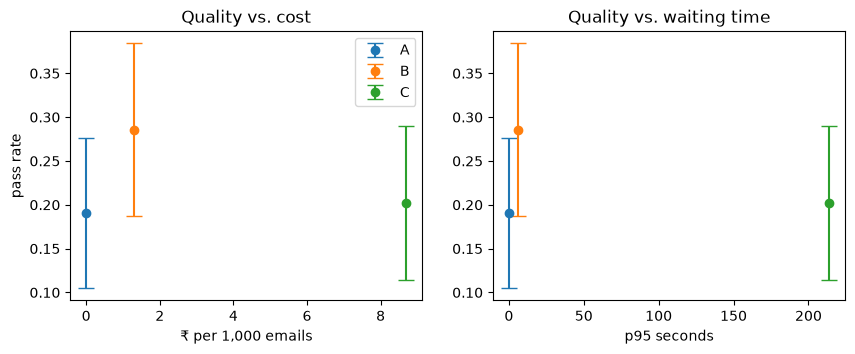

,pass rate,± 2 se,median s,p95 s,tokens per email,"₹ per 1,000 emails",₹ per correct reply
version,,,,,,,
A,0.190,0.086,0.000,0.000,0.000,0.000,0.000
B,0.286,0.099,4.286,6.162,849.893,1.302,0.005
C,0.202,0.088,104.172,213.804,6968.583,8.701,0.043


In [8]:
def row(version, rows):
    passed = np.array([score(by_id[r["id"]], r)["passed"] for r in rows], dtype=float)
    p, n = passed.mean(), len(passed)
    secs = [r.get("seconds", 0) for r in rows]
    cost_1000 = 1000 * np.mean([cost_inr(r.get("tokens_in", 0), r.get("tokens_out", 0)) for r in rows])
    return {"version": version, "pass rate": p, "± 2 se": 2 * np.sqrt(p * (1 - p) / n),
            "median s": percentile(secs, 50), "p95 s": percentile(secs, 95),
            "tokens per email": np.mean([r.get("tokens_in", 0) + r.get("tokens_out", 0) for r in rows]),
            "₹ per 1,000 emails": cost_1000, "₹ per correct reply": cost_1000 / 1000 / p if p else float("inf")}

table = pd.DataFrame([row("A", load_results("A")), row("B", load_results("B")), row("C", c_rows)]).set_index("version")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for name, r in table.iterrows():
    ax[0].errorbar(r["₹ per 1,000 emails"], r["pass rate"], yerr=r["± 2 se"], fmt="o", capsize=6, label=name)
    ax[1].errorbar(r["p95 s"], r["pass rate"], yerr=r["± 2 se"], fmt="o", capsize=6, label=name)
ax[0].set(xlabel="₹ per 1,000 emails", ylabel="pass rate", title="Quality vs. cost")
ax[1].set(xlabel="p95 seconds", title="Quality vs. waiting time"); ax[0].legend(); plt.show()
table.round(3)

**Which version would you ship today, and what would change your mind?** None ships. C is the only version that escalates. Fix routing, then re-measure.

The table ranks B first (29% ± 10%, p95 6 s, ₹1.30 per 1,000 emails), but the pass rate hides the ship blocker: of the 40 cases that need a human, A escalates none and B escalates 2. C escalates 23 (and 9 that did not need it), at a p95 of 214 s and about 7× B's cost, and still passes only 20% ± 9%. No gap between the three is bigger than the error bars.

What would change my mind: every number here comes from one small local model (`qwen3:4b`) at temperature 0; no larger or frontier model has been tested. I would re-run the same 84 cases on other local models with tool-call support, and on one capable model, after the routing fix. A version that misses no escalations, with a pass rate clearly above the others' error bars and a p95 a customer would accept, goes to a pilot.

In [9]:
# ✅ Self-check: run me last. A clear message tells you what to fix.
assert percentile([5, 1, 3, 2, 4], 50) == 3, "percentile(): the median of 1..5 is 3"
assert percentile([1, 2, 3, 4, 5, 6, 7, 8, 9, 10], 95) == 10
assert None not in (PRICE_IN_USD, PRICE_OUT_USD, INR_PER_USD), "Step 3: fill in the prices"
assert len(table) == 3 and len(c_rows) == len(cases)
print("All checks passed ✅  Now write 'In my words' in README.md and record your video.")

All checks passed ✅  Now write 'In my words' in README.md and record your video.
